In [1]:
import pandas as pd
import numpy as np

In [ ]:
app_train= pd.read_csv("data/application_train.csv")
display(app_train.head())

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


The application_train.csv dataset is part of the Home Credit Default Risk dataset. It contains information about loan applicants, including their personal details, financial status, loan amounts, and credit history. It is used to predict whether a loan applicant is likely to have difficulty repaying a loan.

Description of Important Columns
Column	Description

SK_ID_CURR	Unique identification number of each loan applicant.

TARGET	Indicates loan repayment difficulty: 0 means no recorded difficulty, and 1 means the applicant had repayment difficulties.

NAME_CONTRACT_TYPE	Type of loan, such as cash loan or revolving loan.

CODE_GENDER	Gender of the applicant.

FLAG_OWN_CAR	Indicates whether the applicant owns a car.

FLAG_OWN_REALTY	Indicates whether the applicant owns a house or other property.

CNT_CHILDREN	Number of children the applicant has.

AMT_INCOME_TOTAL	Total income of the applicant.

AMT_CREDIT	Total credit amount of the loan.

AMT_ANNUITY	Annual loan payment amount.

FLAG_DOCUMENT_18	Indicates whether document 18 was provided.

FLAG_DOCUMENT_19	Indicates whether document 19 was provided.

FLAG_DOCUMENT_20	Indicates whether document 20 was provided.

FLAG_DOCUMENT_21	Indicates whether document 21 was provided.

AMT_REQ_CREDIT_BUREAU_HOUR	Number of credit bureau enquiries during the previous hour.

AMT_REQ_CREDIT_BUREAU_DAY	Number of credit bureau enquiries during the previous day.

AMT_REQ_CREDIT_BUREAU_WEEK	Number of credit bureau enquiries during the previous week.

AMT_REQ_CREDIT_BUREAU_MON	Number of credit bureau enquiries during the previous month.

AMT_REQ_CREDIT_BUREAU_QRT	Number of credit bureau enquiries during the previous quarter.

AMT_REQ_CREDIT_BUREAU_YEAR	Number of credit bureau enquiries during the previous year.


In [3]:
print(app_train.shape)

(307511, 122)


The dataset contains 307,511 loan applications and 122 features (columns).

In [4]:
app_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), str(16)
memory usage: 325.2 MB


The `app_train.info()` function provides a summary of the dataset, including the number of rows and columns, column names, data types, and memory usage. The output shows that the dataset contains 307,511 entries and 122 columns. Among these columns, 65 are of type `float64`, 41 are of type `int64`, and 16 are of type `str`. The dataset occupies approximately 325.2 MB of memory. This information helps us understand the dataset structure and identify the data types before performing data preprocessing and analysis.

In [5]:
app_train.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,...,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,...,0.008130,0.000595,0.000507,0.000335,0.006402,0.007000,0.034362,0.267395,0.265474,1.899974
std,102790.175348,0.272419,0.722121,2.371231e+05,4.024908e+05,14493.737315,3.694465e+05,0.013831,4363.988632,141275.766519,...,0.089798,0.024387,0.022518,0.018299,0.083849,0.110757,0.204685,0.916002,0.794056,1.869295
min,100002.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000290,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189145.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16524.000000,2.385000e+05,0.010006,-19682.000000,-2760.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278202.000000,0.000000,0.000000,1.471500e+05,5.135310e+05,24903.000000,4.500000e+05,0.018850,-15750.000000,-1213.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367142.500000,0.000000,1.000000,2.025000e+05,8.086500e+05,34596.000000,6.795000e+05,0.028663,-12413.000000,-289.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,19.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7489.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


The `app_train.describe()` function generates descriptive statistics for the numerical columns in the dataset. It displays values such as count, mean, standard deviation, minimum, maximum, and quartiles (25%, 50%, and 75%). The output shows statistics for 106 numerical columns out of the 122 total columns. Some columns have fewer valid entries than the total number of rows, indicating missing values. These statistics help us understand the distribution, variation, and range of the data and identify possible outliers before further analysis.

In [7]:
app_train.isna()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,True,True,True,True,True
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
307506,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,True,True,True,True,True
307507,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,True,True,True,True,True
307508,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
307509,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


The `app_train.isna()` function checks for missing values in the dataset. It returns a DataFrame of Boolean values, where `True` indicates a missing value (`NaN`) and `False` indicates a non-missing value. The output contains 307,511 rows and 122 columns, matching the original dataset dimensions. For example, row 3 contains missing values in the credit bureau enquiry columns. This function helps identify missing data that may need to be handled during data preprocessing.

In [8]:
app_train.isna().sum()

SK_ID_CURR                        0
TARGET                            0
NAME_CONTRACT_TYPE                0
CODE_GENDER                       0
FLAG_OWN_CAR                      0
                              ...  
AMT_REQ_CREDIT_BUREAU_DAY     41519
AMT_REQ_CREDIT_BUREAU_WEEK    41519
AMT_REQ_CREDIT_BUREAU_MON     41519
AMT_REQ_CREDIT_BUREAU_QRT     41519
AMT_REQ_CREDIT_BUREAU_YEAR    41519
Length: 122, dtype: int64

The `app_train.isna().sum()` function calculates the total number of missing values in each column of the dataset. The output shows the missing value count for all 122 columns. For example, the columns `AMT_REQ_CREDIT_BUREAU_DAY`, `AMT_REQ_CREDIT_BUREAU_WEEK`, `AMT_REQ_CREDIT_BUREAU_MON`, `AMT_REQ_CREDIT_BUREAU_QRT`, and `AMT_REQ_CREDIT_BUREAU_YEAR` each contain 41,519 missing values. Columns with a count of zero have no missing values. This analysis helps identify columns that require missing-value treatment during data preprocessing.

In [9]:
app_train.duplicated().sum()

np.int64(0)

there are no duplicate rows in the dataset. This means every row is unique, so no duplicate-row removal is required.

In [10]:
app_train.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'FLAG_MOBIL',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'OCCUPATION_TYPE',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'WEEKDAY_APPR_PROCESS_START',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'ORGANIZATION_TYPE',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_BEGINEXPLUATATION_A

The app_train.columns.tolist() function returns the names of all columns in the dataset as a Python list. The output contains 122 column names, including SK_ID_CURR, TARGET, AMT_INCOME_TOTAL, and AMT_CREDIT

In [11]:
print("Duplicate rows:", app_train.duplicated().sum())
print("Duplicate applicant IDs:", app_train["SK_ID_CURR"].duplicated().sum())

Duplicate rows: 0
Duplicate applicant IDs: 0


there are no duplicate rows in the dataset. 

In [12]:
check_cols = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "DAYS_EMPLOYED",
    "DAYS_BIRTH"
]

display(app_train[check_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
AMT_ANNUITY,307499.0,27108.573909,14493.737315,1615.5,16524.0,24903.0,34596.0,258025.5
AMT_GOODS_PRICE,307233.0,538396.207429,369446.460540,40500.0,238500.0,450000.0,679500.0,4050000.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
CNT_FAM_MEMBERS,307509.0,2.152665,0.910682,1.0,2.0,2.0,3.0,20.0
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-17912.0,-2760.0,-1213.0,-289.0,365243.0
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-25229.0,-19682.0,-15750.0,-12413.0,-7489.0


The code displays descriptive statistics for eight selected columns related to income, loans, family, employment, and age. The `.describe()` function calculates count, mean, standard deviation, minimum, maximum, and quartiles, while `.T` transposes the table for easier reading. The output helps identify missing values and unusual data points.

In [13]:
# Select numerical columns, excluding target and applicant ID
numeric_cols = app_train.select_dtypes(
    include="number"
).columns.drop(
    ["TARGET", "SK_ID_CURR"],
    errors="ignore"
)

outlier_results = []

for col in numeric_cols:
    data = app_train[col].dropna()

    if data.empty:
        continue

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((data < lower) | (data > upper)).sum()

    outlier_results.append({
        "Column": col,
        "Outlier_Count": count,
        "Outlier_Percentage": round(
            count / len(data) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary = outlier_summary.sort_values(
    "Outlier_Percentage",
    ascending=False
)

display(outlier_summary)

,Column,Outlier_Count,Outlier_Percentage
18,REGION_RATING_CLIENT,80527,26.19
19,REGION_RATING_CLIENT_W_CITY,78027,25.37
7,DAYS_EMPLOYED,72217,23.48
25,REG_CITY_NOT_WORK_CITY,70867,23.05
13,FLAG_WORK_PHONE,61308,19.94
...,...,...,...
11,FLAG_MOBIL,1,0.00
86,FLAG_DOCUMENT_10,7,0.00
79,FLAG_DOCUMENT_3,0,0.00
78,FLAG_DOCUMENT_2,13,0.00


The code identifies outliers in 104 numerical columns using the IQR method, excluding `TARGET` and `SK_ID_CURR`. It calculates the number and percentage of outliers in each column and sorts the results in descending order. The output shows that `REGION_RATING_CLIENT` has the highest outlier percentage (26.19%), followed by `REGION_RATING_CLIENT_W_CITY` (25.37%) and `DAYS_EMPLOYED` (23.48%). These results help identify unusual values for further analysis and preprocessing.

In [14]:
continuous_cols = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "OWN_CAR_AGE",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "TOTALAREA_MODE"
]

outlier_results = []

for col in continuous_cols:
    data = app_train[col].dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((data < lower) | (data > upper)).sum()

    outlier_results.append({
        "Column": col,
        "Outlier_Count": count,
        "Outlier_Percentage": round(
            count / len(data) * 100, 2
        )
    })

display(
    pd.DataFrame(outlier_results)
    .sort_values("Outlier_Percentage", ascending=False)
)

,Column,Outlier_Count,Outlier_Percentage
8,TOTALAREA_MODE,12091,7.60
3,AMT_GOODS_PRICE,14728,4.79
4,OWN_CAR_AGE,4932,4.72
0,AMT_INCOME_TOTAL,14035,4.56
2,AMT_ANNUITY,7504,2.44
1,AMT_CREDIT,6562,2.13
5,EXT_SOURCE_1,0,0.00
6,EXT_SOURCE_2,0,0.00
7,EXT_SOURCE_3,0,0.00


The code identifies outliers in nine continuous numerical columns using the IQR method and calculates their counts and percentages. The results show that `TOTALAREA_MODE` has the highest outlier percentage (7.60%), followed by `AMT_GOODS_PRICE` (4.79%) and `OWN_CAR_AGE` (4.72%). No outliers were detected in `EXT_SOURCE_1`, `EXT_SOURCE_2`, or `EXT_SOURCE_3` using this method. These results help identify unusual values for further analysis and preprocessing.

In [15]:
print(app_train.dtypes.value_counts())

float64    65
int64      41
str        16
Name: count, dtype: int64


The `app_train.dtypes.value_counts()` function counts the number of columns for each data type in the dataset. The output shows 65 `float64` columns, 41 `int64` columns, and 16 `str` columns, making a total of 122 columns. This helps understand the data types and determine the appropriate preprocessing techniques for numerical and categorical data.

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns


,count
TARGET,
0,282686
1,24825


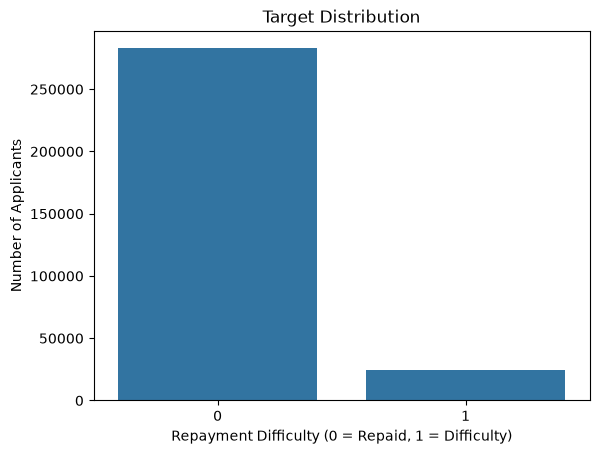

In [17]:
target_counts = app_train["TARGET"].value_counts()
display(target_counts.to_frame("count"))

sns.countplot(data=app_train, x="TARGET")
plt.title("Target Distribution")
plt.xlabel("Repayment Difficulty (0 = Repaid, 1 = Difficulty)")
plt.ylabel("Number of Applicants")
plt.show()

Displays bar chart of Repayment diffculties vs no of applicants

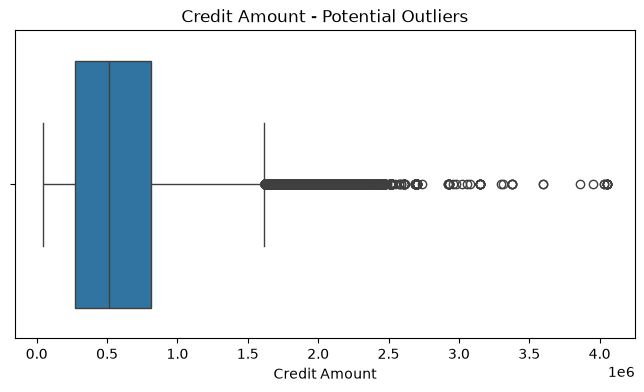

,AMT_CREDIT
0.00,45000.0
0.25,270000.0
0.50,513531.0
0.75,808650.0
0.90,1133748.0
0.95,1350000.0
0.99,1854000.0
1.00,4050000.0


In [18]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=app_train["AMT_CREDIT"])
plt.title("Credit Amount - Potential Outliers")
plt.xlabel("Credit Amount")
plt.show()

display(
    app_train["AMT_CREDIT"]
    .quantile([0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1])
    .to_frame("AMT_CREDIT")
)

Box plotted graph of amt_credited outliners

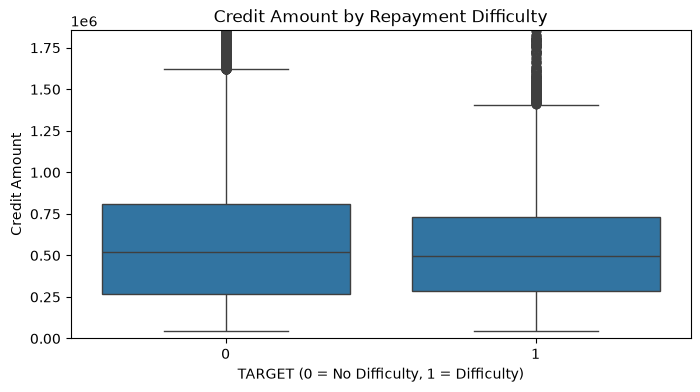

In [19]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=app_train,
    x="TARGET",
    y="AMT_CREDIT"
)

plt.ylim(0, app_train["AMT_CREDIT"].quantile(0.99))
plt.title("Credit Amount by Repayment Difficulty")
plt.xlabel("TARGET (0 = No Difficulty, 1 = Difficulty)")
plt.ylabel("Credit Amount")
plt.show()

Box plotted graph of amt_credited by repayment diffculty outliners

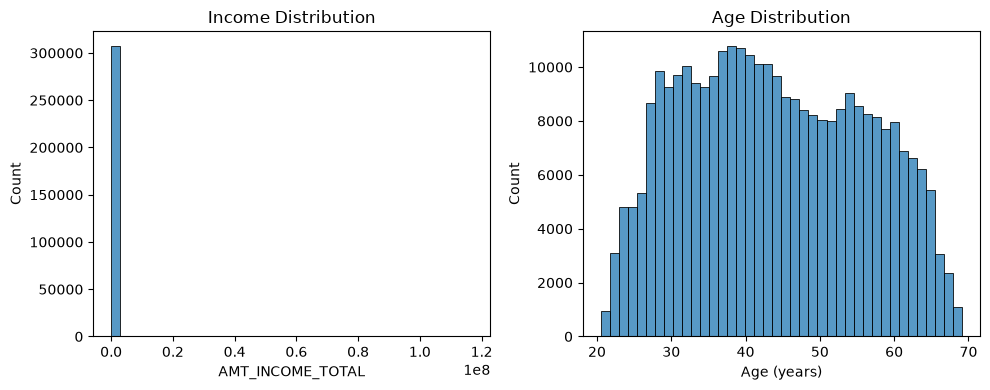

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.histplot(app_train["AMT_INCOME_TOTAL"], bins=40, ax=axes[0])
axes[0].set_title("Income Distribution")

sns.histplot(-app_train["DAYS_BIRTH"] / 365, bins=40, ax=axes[1])
axes[1].set_title("Age Distribution")
axes[1].set_xlabel("Age (years)")

plt.tight_layout()
plt.show()

The first histogram shows the distribution of AMT_INCOME_TOTAL, while the second converts DAYS_BIRTH into age in years by dividing by 365 and changing the sign. The plots help identify the most common income and age ranges, as well as skewness and unusual values in the dataset. plt.tight_layout() adjusts spacing, and plt.show() displays both plots.

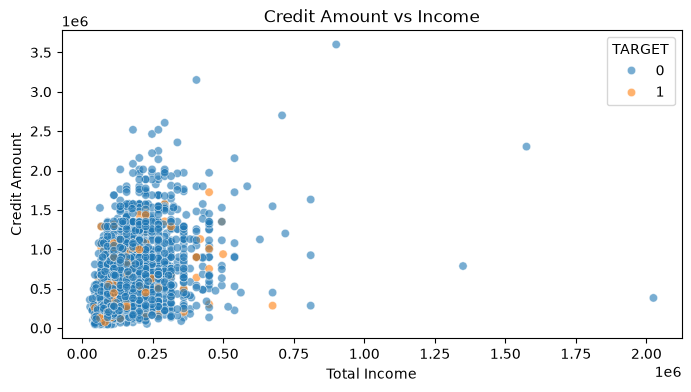

In [21]:
plt.figure(figsize=(8, 4))

sns.scatterplot(
    data=app_train.sample(3000, random_state=42),
    x="AMT_INCOME_TOTAL",
    y="AMT_CREDIT",
    hue="TARGET",
    alpha=0.6
)

plt.title("Credit Amount vs Income")
plt.xlabel("Total Income")
plt.ylabel("Credit Amount")
plt.show()

a scatter plot showing the relationship between applicants' total income (AMT_INCOME_TOTAL) and credit amount (AMT_CREDIT). It randomly selects 3,000 records using random_state=42 for consistent results. The hue="TARGET" parameter uses different colors to distinguish applicants with and without repayment difficulties, while alpha=0.6 adds transparency to the points. The plot helps visualize the relationship between income and credit amount and compare repayment outcomes.

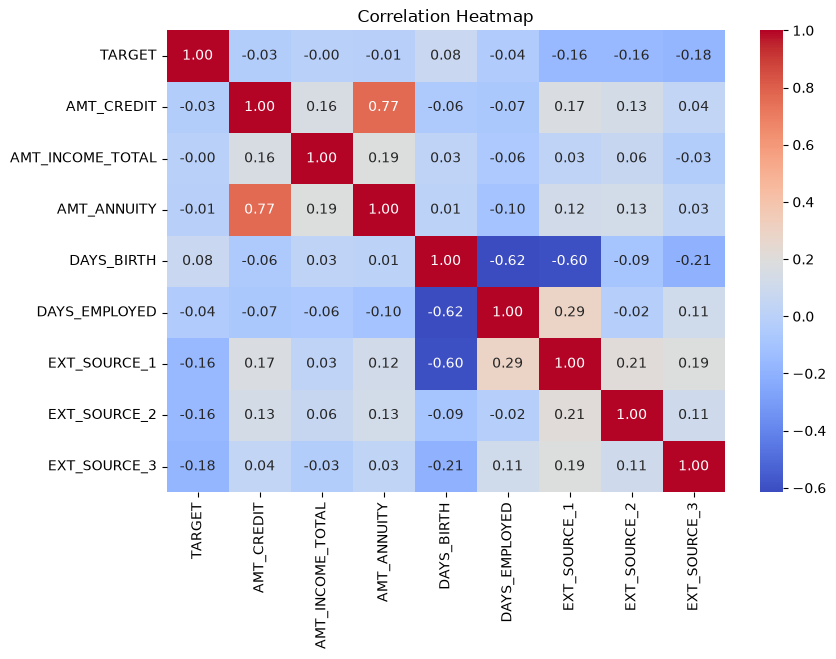

In [22]:
numeric_columns = [
    "TARGET",
    "AMT_CREDIT",
    "AMT_INCOME_TOTAL",
    "AMT_ANNUITY",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3"
]

plt.figure(figsize=(9, 6))

sns.heatmap(
    app_train[numeric_columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

a correlation heatmap for nine numerical columns, including income, credit amount, age, employment days, and external credit scores. The .corr() function calculates the correlation between each pair of variables, while sns.heatmap() displays the results using colors and numerical values rounded to two decimal places. Values closer to +1 indicate a strong positive correlation, values closer to −1 indicate a strong negative correlation, and values near 0 indicate a weak linear relationship. This visualization helps identify relationships between features and the loan repayment target (TARGET).

In [23]:
X = app_train.drop(columns=["TARGET", "SK_ID_CURR"])
y = app_train["TARGET"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (307511, 120)
Target shape: (307511,)


separates the dataset into features (X) and target (y) for machine learning. X contains 120 input columns after removing TARGET and SK_ID_CURR, while y contains the TARGET column, which indicates whether a client experienced payment difficulties. The output confirms that there are 307,511 records, with 120 features for each record and one target value per record.

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (246008, 120)
Testing data: (61503, 120)


This code splits the dataset into 80% training data and 20% testing data. `random_state=42` ensures the same split each time, while `stratify=y` maintains the proportion of target classes in both sets. The output shows 246,008 training records and 61,503 testing records, each with 120 features.

In [25]:
print("Numerical columns:",
      X_train.select_dtypes(include="number").shape[1])

print("Categorical columns:",
      X_train.select_dtypes(include=["object", "str"]).shape[1])

Numerical columns: 104
Categorical columns: 16


Displays no of numericasl and categorical columns

In [27]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = X_train.select_dtypes(include="number").columns
categorical_features = X_train.select_dtypes(
    include=["object", "str"]
).columns

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_scaled = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

Accuracy: 0.691
F1 (class 1): 0.262
              precision    recall  f1-score   support

           0       0.96      0.69      0.80     56538
           1       0.16      0.68      0.26      4965

    accuracy                           0.69     61503
   macro avg       0.56      0.69      0.53     61503
weighted avg       0.90      0.69      0.76     61503



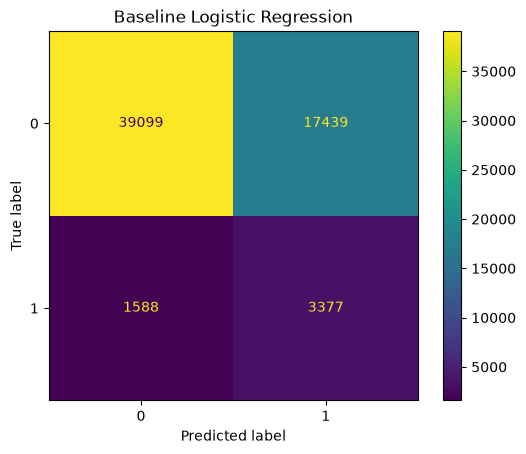

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, ConfusionMatrixDisplay
)

logistic_basic = Pipeline([
    ("preprocessing", preprocessor_scaled),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_basic.fit(X_train, y_train)
basic_pred = logistic_basic.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, basic_pred), 3))
print("F1 (class 1):", round(f1_score(y_test, basic_pred), 3))
print(classification_report(y_test, basic_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, basic_pred)
plt.title("Baseline Logistic Regression")
plt.show()

a baseline Logistic Regression model using scaled/preprocessed features and balanced class weights. The model achieves 69.1% accuracy and an F1-score of 0.262 for class 1. It identifies 68% of clients with payment difficulties (recall), but its precision is only 16%, meaning many predicted defaults are incorrect. The classification report and confusion matrix help assess its performance on both classes.

In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

rf_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:", round(accuracy_score(y_test, rf_pred), 3))
print("Random Forest F1 (class 1):", round(f1_score(y_test, rf_pred), 3))

NameError: name 'preprocessor' is not defined

In [ ]:
bureau = pd.read_csv("data/bureau.csv")

print("Shape:", bureau.shape)
display(bureau.head())

In [ ]:
bureau_agg = bureau.groupby("SK_ID_CURR").agg(
    BUREAU_LOAN_COUNT=("SK_ID_BUREAU", "count"),
    BUREAU_ACTIVE_COUNT=("CREDIT_ACTIVE", lambda x: (x == "Active").sum()),
    BUREAU_CREDIT_SUM=("AMT_CREDIT_SUM", "sum"),
    BUREAU_DEBT_SUM=("AMT_CREDIT_SUM_DEBT", "sum"),
    BUREAU_OVERDUE_SUM=("AMT_CREDIT_SUM_OVERDUE", "sum"),
    BUREAU_MAX_OVERDUE_DAYS=("CREDIT_DAY_OVERDUE", "max")
).reset_index()

print("Aggregated shape:", bureau_agg.shape)
display(bureau_agg.head())

In [ ]:
app_train_hist = app_train.merge(
    bureau_agg,
    on="SK_ID_CURR",
    how="left"
)

print("Original shape:", app_train.shape)
print("With historical features:", app_train_hist.shape)

In [ ]:
print("Merged shape:", app_train_hist.shape)
print("Missing historical values:")
display(app_train_hist[bureau_agg.columns.drop("SK_ID_CURR")].isna().sum())


In [ ]:
X_hist = app_train_hist.drop(columns=["TARGET", "SK_ID_CURR"])
y_hist = app_train_hist["TARGET"]

X_train_hist, X_test_hist, y_train_hist, y_test_hist = train_test_split(
    X_hist,
    y_hist,
    test_size=0.2,
    random_state=42,
    stratify=y_hist
)

print("Training shape:", X_train_hist.shape)
print("Testing shape:", X_test_hist.shape)

In [ ]:
numeric_features_hist = X_train_hist.select_dtypes(include="number").columns
categorical_features_hist = X_train_hist.select_dtypes(
    include=["object", "str"]
).columns

numeric_pipeline_hist = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_hist = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_hist = ColumnTransformer([
    ("num", numeric_pipeline_hist, numeric_features_hist),
    ("cat", categorical_pipeline_hist, categorical_features_hist)
])

print("Updated preprocessing pipeline ready.")

In [ ]:
logistic_hist = Pipeline([
    ("preprocessing", preprocessor_hist),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_hist.fit(X_train_hist, y_train_hist)
hist_pred = logistic_hist.predict(X_test_hist)

print("Accuracy:", round(accuracy_score(y_test_hist, hist_pred), 3))
print("F1 (class 1):", round(f1_score(y_test_hist, hist_pred), 3))
print(classification_report(y_test_hist, hist_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test_hist, hist_pred)
plt.title("Logistic Regression with Bureau Features")
plt.show()

In [ ]:
previous_app = pd.read_csv("data/previous_application.csv")

print("Shape:", previous_app.shape)
display(previous_app.head())

In [ ]:
previous_agg = previous_app.groupby("SK_ID_CURR").agg(
    PREV_APP_COUNT=("SK_ID_PREV", "count"),
    PREV_APPROVED_COUNT=("NAME_CONTRACT_STATUS", lambda x: (x == "Approved").sum()),
    PREV_REFUSED_COUNT=("NAME_CONTRACT_STATUS", lambda x: (x == "Refused").sum()),
    PREV_CREDIT_SUM=("AMT_CREDIT", "sum"),
    PREV_CREDIT_MEAN=("AMT_CREDIT", "mean"),
    PREV_APPLICATION_MEAN=("AMT_APPLICATION", "mean")
).reset_index()

print("Shape:", previous_agg.shape)
display(previous_agg.head())

In [ ]:
app_train_full = app_train.merge(
    bureau_agg, on="SK_ID_CURR", how="left"
)

app_train_full = app_train_full.merge(
    previous_agg, on="SK_ID_CURR", how="left"
)

print("Shape:", app_train_full.shape)

In [ ]:
X_full = app_train_full.drop(columns=["TARGET", "SK_ID_CURR"])
y_full = app_train_full["TARGET"]

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full, y_full,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)

print("Training shape:", X_train_full.shape)
print("Validation shape:", X_test_full.shape)

In [ ]:
numeric_features_full = X_train_full.select_dtypes(include="number").columns
categorical_features_full = X_train_full.select_dtypes(
    include=["object", "str"]
).columns

numeric_pipeline_full = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_full = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_full = ColumnTransformer([
    ("num", numeric_pipeline_full, numeric_features_full),
    ("cat", categorical_pipeline_full, categorical_features_full)
])

print("Numeric features:", len(numeric_features_full))
print("Categorical features:", len(categorical_features_full))

Accuracy: 0.696
F1 (class 1): 0.267
              precision    recall  f1-score   support

           0       0.96      0.70      0.81     56538
           1       0.17      0.69      0.27      4965

    accuracy                           0.70     61503
   macro avg       0.56      0.69      0.54     61503
weighted avg       0.90      0.70      0.76     61503



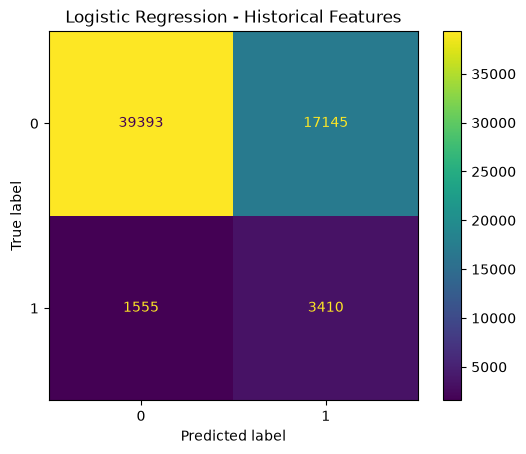

In [67]:
logistic_full = Pipeline([
    ("preprocessing", preprocessor_full),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_full.fit(X_train_full, y_train_full)

full_pred = logistic_full.predict(X_test_full)

print("Accuracy:", round(accuracy_score(y_test_full, full_pred), 3))
print("F1 (class 1):", round(f1_score(y_test_full, full_pred), 3))
print(classification_report(y_test_full, full_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test_full, full_pred)
plt.title("Logistic Regression - Historical Features")
plt.show()

a Logistic Regression model using the full preprocessing pipeline and historical features. It achieves 69.6% accuracy and an F1-score of 0.267 for class 1, showing a slight improvement over the baseline model. The classification report and confusion matrix evaluate how well it identifies clients with payment difficulties.

Accuracy: 0.736
F1 (class 1): 0.269
              precision    recall  f1-score   support

           0       0.96      0.75      0.84     56538
           1       0.17      0.60      0.27      4965

    accuracy                           0.74     61503
   macro avg       0.56      0.68      0.55     61503
weighted avg       0.89      0.74      0.79     61503



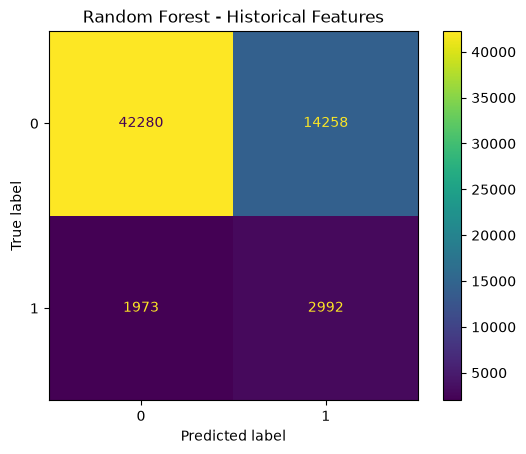

In [69]:
rf_full = Pipeline([
    ("preprocessing", preprocessor_full),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

rf_full.fit(X_train_full, y_train_full)

rf_full_pred = rf_full.predict(X_test_full)

print("Accuracy:", round(accuracy_score(y_test_full, rf_full_pred), 3))
print("F1 (class 1):", round(f1_score(y_test_full, rf_full_pred), 3))
print(classification_report(y_test_full, rf_full_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test_full, rf_full_pred)
plt.title("Random Forest - Historical Features")
plt.show()

trains a Random Forest model using historical features, with 100 trees and a maximum depth of 12. It achieves 73.6% accuracy and an F1-score of 0.269 for class 1. Compared with Logistic Regression, it improves overall accuracy slightly, but its recall for clients with payment difficulties drops to 60%. The classification report and confusion matrix show how well the model predicts both classes.

In [70]:
installments = pd.read_csv("data/installments_payments.csv")

print("Shape:", installments.shape)
display(installments.head())

Shape: (13605401, 8)


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


loads the installments_payments.csv dataset, which contains information about clients’ loan installment payments. The dataset has 13,605,401 rows and 8 columns. head() displays the first five rows to inspect the data and understand its structure
shows the first five records of the installment payment dataset. It includes loan IDs, installment numbers, scheduled and actual payment dates, and installment and payment amounts. These details help identify late payments and differences between the amount due and the amount paid.

In [71]:
installments["LATE_DAYS"] = (
    installments["DAYS_ENTRY_PAYMENT"] -
    installments["DAYS_INSTALMENT"]
).clip(lower=0)

installments["PAYMENT_DIFF"] = (
    installments["AMT_INSTALMENT"] -
    installments["AMT_PAYMENT"]
).clip(lower=0)

installments_agg = installments.groupby("SK_ID_CURR").agg(
    INSTALMENT_COUNT=("SK_ID_PREV", "count"),
    LATE_DAYS_MEAN=("LATE_DAYS", "mean"),
    LATE_PAYMENT_COUNT=("LATE_DAYS", lambda x: (x > 0).sum()),
    PAYMENT_DIFF_MEAN=("PAYMENT_DIFF", "mean")
).reset_index()

print("Shape:", installments_agg.shape)
display(installments_agg.head())


Shape: (339587, 5)


,SK_ID_CURR,INSTALMENT_COUNT,LATE_DAYS_MEAN,LATE_PAYMENT_COUNT,PAYMENT_DIFF_MEAN
0,100001,7,1.571429,1,0.0
1,100002,19,0.000000,0,0.0
2,100003,25,0.000000,0,0.0
3,100004,3,0.000000,0,0.0
4,100005,9,0.111111,1,0.0


calculates late payment days and unpaid installment amounts, then groups the data by client to find the total number of installments, average delay, number of late payments, and average payment difference. The output contains 339,587 clients and 5 columns, summarizing each client’s payment history.

In [72]:
app_train_full = app_train_full.merge(
    installments_agg,
    on="SK_ID_CURR",
    how="left"
)

print("Shape:", app_train_full.shape)

Shape: (307511, 138)


merges the installment payment summary features into app_train_full using SK_ID_CURR as the common key. A left join keeps all 307,511 original client records and adds the payment history features, resulting in 138 columns.

In [73]:
credit_card = pd.read_csv("data/credit_card_balance.csv")

print("Shape:", credit_card.shape)
display(credit_card.head())

Shape: (3840312, 23)


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,...,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,...,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,...,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,...,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,...,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


loads the credit card balance dataset, which contains 3,840,312 rows and 23 columns. The first five rows show clients’ credit balances, credit limits, spending activity, payment status, and overdue payment information. These features help analyze credit card usage and repayment behaviour.

In [74]:
credit_agg = credit_card.groupby("SK_ID_CURR").agg(
    CC_RECORD_COUNT=("SK_ID_PREV", "count"),
    CC_BALANCE_MEAN=("AMT_BALANCE", "mean"),
    CC_LIMIT_MEAN=("AMT_CREDIT_LIMIT_ACTUAL", "mean"),
    CC_DRAWINGS_MEAN=("AMT_DRAWINGS_CURRENT", "mean"),
    CC_DPD_MAX=("SK_DPD", "max"),
    CC_DPD_DEF_MAX=("SK_DPD_DEF", "max")
).reset_index()

print("Shape:", credit_agg.shape)
display(credit_agg.head())

Shape: (103558, 7)


,SK_ID_CURR,CC_RECORD_COUNT,CC_BALANCE_MEAN,CC_LIMIT_MEAN,CC_DRAWINGS_MEAN,CC_DPD_MAX,CC_DPD_DEF_MAX
0,100006,6,0.000000,270000.000000,0.000000,0,0
1,100011,74,54482.111149,164189.189189,2432.432432,0,0
2,100013,96,18159.919219,131718.750000,5953.125000,1,1
3,100021,17,0.000000,675000.000000,0.000000,0,0
4,100023,8,0.000000,135000.000000,0.000000,0,0


groups credit card records by client and calculates the number of records, average balance, average credit limit, average spending, and maximum overdue days. The output contains 103,558 clients and 7 columns, summarizing each client’s credit card usage and repayment behaviour.

In [75]:
app_train_full = app_train_full.merge(
    credit_agg,
    on="SK_ID_CURR",
    how="left"
)

print("Shape:", app_train_full.shape)

Shape: (307511, 144)


merges the credit card summary features into app_train_full using SK_ID_CURR as the common key. The left join keeps all 307,511 client records and adds the credit card usage and repayment features, increasing the dataset to 144 columns.

In [76]:
X_full = app_train_full.drop(columns=["TARGET", "SK_ID_CURR"])
y_full = app_train_full["TARGET"]

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)

print("Training shape:", X_train_full.shape)
print("Validation shape:", X_test_full.shape)

Training shape: (246008, 142)
Validation shape: (61503, 142)


separates the full dataset into features (X_full) and the target (y_full), then splits it into 80% training data and 20% validation data. Using stratify=y_full preserves the target class proportions in both sets. The output shows 246,008 training records and 61,503 validation records, each containing 142 features

In [77]:
numeric_features_full = X_train_full.select_dtypes(include="number").columns
categorical_features_full = X_train_full.select_dtypes(
    include=["object", "str"]
).columns

numeric_pipeline_full = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_full = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_full = ColumnTransformer([
    ("num", numeric_pipeline_full, numeric_features_full),
    ("cat", categorical_pipeline_full, categorical_features_full)
])

print("Numeric features:", len(numeric_features_full))
print("Categorical features:", len(categorical_features_full))

Numeric features: 126
Categorical features: 16


Describes numeric features and categorical features

Accuracy: 0.701
F1 (class 1): 0.272
              precision    recall  f1-score   support

           0       0.96      0.70      0.81     56538
           1       0.17      0.69      0.27      4965

    accuracy                           0.70     61503
   macro avg       0.57      0.70      0.54     61503
weighted avg       0.90      0.70      0.77     61503



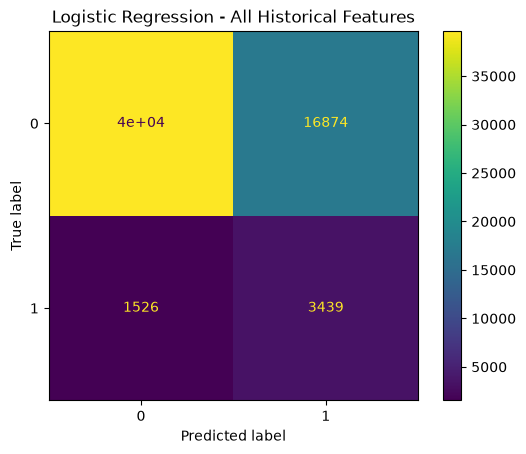

In [78]:
logistic_full = Pipeline([
    ("preprocessing", preprocessor_full),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_full.fit(X_train_full, y_train_full)

full_pred = logistic_full.predict(X_test_full)

print("Accuracy:", round(accuracy_score(y_test_full, full_pred), 3))
print("F1 (class 1):", round(f1_score(y_test_full, full_pred), 3))
print(classification_report(y_test_full, full_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test_full, full_pred)
plt.title("Logistic Regression - All Historical Features")
plt.show()


trains a Logistic Regression model using all available features, including historical installment and credit card data. It achieves 70.1% accuracy and an F1-score of 0.272 for class 1. The model identifies 69% of clients with payment difficulties, but its precision is only 17%. The classification report and confusion matrix help evaluate its prediction performance.

Accuracy: 0.744
F1 (class 1): 0.276
              precision    recall  f1-score   support

           0       0.96      0.76      0.84     56538
           1       0.18      0.60      0.28      4965

    accuracy                           0.74     61503
   macro avg       0.57      0.68      0.56     61503
weighted avg       0.89      0.74      0.80     61503



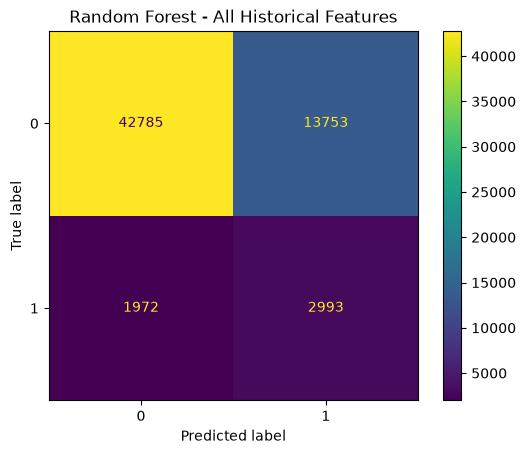

In [79]:
rf_full = Pipeline([
    ("preprocessing", preprocessor_full),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=12,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
])

rf_full.fit(X_train_full, y_train_full)

rf_full_pred = rf_full.predict(X_test_full)

print("Accuracy:", round(accuracy_score(y_test_full, rf_full_pred), 3))
print("F1 (class 1):", round(f1_score(y_test_full, rf_full_pred), 3))
print(classification_report(y_test_full, rf_full_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test_full, rf_full_pred)
plt.title("Random Forest - All Historical Features")
plt.show()

trains a Random Forest model using all available features, including historical payment and credit card data. It achieves 74.4% accuracy and an F1-score of 0.276 for class 1, performing slightly better than Logistic Regression. It identifies 60% of clients with payment difficulties, while the classification report and confusion matrix help evaluate its predictions.

In [80]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_dist = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [8, 12, 16],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.5]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

rf_search = RandomizedSearchCV(
    estimator=rf_full,
    param_distributions=param_dist,
    n_iter=8,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=1,
    verbose=2
)

print("Random Forest search is ready.")

Random Forest search is ready.


In [82]:
param_dist = {
    "model__n_estimators": [100],
    "model__max_depth": [8, 12],
    "model__min_samples_split": [5, 10],
    "model__min_samples_leaf": [2, 5]
}

rf_search = RandomizedSearchCV(
    estimator=rf_full,
    param_distributions=param_dist,
    n_iter=3,
    scoring="f1",
    cv=2,
    random_state=42,
    n_jobs=1,
    verbose=2
)

In [83]:
rf_search.fit(X_train_full, y_train_full)

print("Best parameters:", rf_search.best_params_)
print("Best CV F1:", round(rf_search.best_score_, 3))

Fitting 2 folds for each of 3 candidates, totalling 6 fits
[CV] END model__max_depth=8, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=100; total time= 1.7min
[CV] END model__max_depth=8, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=100; total time= 1.7min
[CV] END model__max_depth=12, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=100; total time= 2.1min
[CV] END model__max_depth=12, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=100; total time= 1.9min
[CV] END model__max_depth=8, model__min_samples_leaf=2, model__min_samples_split=5, model__n_estimators=100; total time= 1.7min
[CV] END model__max_depth=8, model__min_samples_leaf=2, model__min_samples_split=5, model__n_estimators=100; total time= 1.7min
Best parameters: {'model__n_estimators': 100, 'model__min_samples_split': 10, 'model__min_samples_leaf': 2, 'model__max_depth': 12}
Best CV F1: 0.276


uses RandomizedSearchCV to test different Random Forest settings, such as tree depth and minimum samples per split or leaf. It evaluates three combinations using 2-fold cross-validation and the F1-score to find the best parameters for identifying clients with payment difficulties. The output displays the best parameter combination and its average cross-validation F1-score.

In [84]:
best_rf = rf_search.best_estimator_

tuned_pred = best_rf.predict(X_test_full)

print("Accuracy:", round(accuracy_score(y_test_full, tuned_pred), 3))
print("F1 (class 1):", round(f1_score(y_test_full, tuned_pred), 3))
print(classification_report(y_test_full, tuned_pred, zero_division=0))

Accuracy: 0.745
F1 (class 1): 0.278
              precision    recall  f1-score   support

           0       0.96      0.76      0.85     56538
           1       0.18      0.61      0.28      4965

    accuracy                           0.74     61503
   macro avg       0.57      0.68      0.56     61503
weighted avg       0.89      0.74      0.80     61503



selects the best Random Forest model found during hyperparameter tuning and evaluates it on the test data. It achieves 74.5% accuracy and an F1-score of 0.278 for class 1, with 61% recall for clients experiencing payment difficulties. The results show a slight improvement over the previous Random Forest model.

In [85]:
rf_probs = best_rf.predict_proba(X_test_full)[:, 1]

for threshold in [0.2, 0.3, 0.4, 0.5]:
    pred = (rf_probs >= threshold).astype(int)

    print(
        "Threshold:", threshold,
        "| F1:", round(f1_score(y_test_full, pred), 3),
        "| Precision:", round(precision_score(y_test_full, pred), 3),
        "| Recall:", round(recall_score(y_test_full, pred), 3)
    )

Threshold: 0.2 | F1: 0.153 | Precision: 0.083 | Recall: 0.997
Threshold: 0.3 | F1: 0.177 | Precision: 0.098 | Recall: 0.951
Threshold: 0.4 | F1: 0.222 | Precision: 0.128 | Recall: 0.818
Threshold: 0.5 | F1: 0.278 | Precision: 0.18 | Recall: 0.607


tests different probability thresholds (0.2, 0.3, 0.4, and 0.5) to classify clients as likely to face payment difficulties. The results show that lower thresholds increase recall but reduce precision and F1-score, while a higher threshold improves precision and F1-score but misses more clients with payment difficulties.

In [86]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__max_depth": [12, 16],
    "model__min_samples_split": [10],
    "model__min_samples_leaf": [2],
    "model__n_estimators": [100]
}

grid_search = GridSearchCV(
    estimator=rf_full,
    param_grid=param_grid,
    scoring="f1",
    cv=2,
    n_jobs=1,
    verbose=2
)

print("Grid Search is ready!")

Grid Search is ready!


In [87]:
grid_search.fit(X_train_full, y_train_full)

print("Best parameters:", grid_search.best_params_)
print("Best CV F1:", round(grid_search.best_score_, 3))

Fitting 2 folds for each of 2 candidates, totalling 4 fits
[CV] END model__max_depth=12, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=100; total time= 2.0min
[CV] END model__max_depth=12, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=100; total time= 2.2min
[CV] END model__max_depth=16, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=100; total time= 2.5min
[CV] END model__max_depth=16, model__min_samples_leaf=2, model__min_samples_split=10, model__n_estimators=100; total time= 2.4min
Best parameters: {'model__max_depth': 16, 'model__min_samples_leaf': 2, 'model__min_samples_split': 10, 'model__n_estimators': 100}
Best CV F1: 0.284


runs GridSearchCV to compare two Random Forest configurations using 2-fold cross-validation, evaluating four fits in total. The best model uses 100 trees, a maximum depth of 16, a minimum of 2 samples per leaf, and 10 samples per split, achieving a best cross-validation F1-score of 0.284.

In [89]:
best_grid_rf = grid_search.best_estimator_

grid_pred = best_grid_rf.predict(X_test_full)

print("Accuracy:", round(accuracy_score(y_test_full, grid_pred), 3))
print("F1 (class 1):", round(f1_score(y_test_full, grid_pred), 3))
print(classification_report(y_test_full, grid_pred, zero_division=0))

Accuracy: 0.805
F1 (class 1): 0.288
              precision    recall  f1-score   support

           0       0.95      0.83      0.89     56538
           1       0.20      0.49      0.29      4965

    accuracy                           0.80     61503
   macro avg       0.58      0.66      0.59     61503
weighted avg       0.89      0.80      0.84     61503



code evaluates the best Random Forest model selected by Grid Search on the test data. It achieves 80.5% accuracy and an F1-score of 0.288 for class 1. The model correctly identifies 49% of clients with payment difficulties, showing improved overall accuracy, though it still misses some clients at risk of default.

In [90]:
%pip install shap


Note: you may need to restart the kernel to use updated packages.


In [91]:
import shap
import numpy as np
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.52.0


In [92]:
X_sample = X_test_full.sample(200, random_state=42)

X_transformed = best_grid_rf.named_steps["preprocessing"].transform(X_sample)

feature_names = best_grid_rf.named_steps[
    "preprocessing"
].get_feature_names_out()

explainer = shap.TreeExplainer(
    best_grid_rf.named_steps["model"]
)

shap_values = explainer.shap_values(X_transformed)

print("SHAP values calculated!")

SHAP values calculated!


uses SHAP (SHapley Additive exPlanations) to explain the Random Forest model’s predictions for a sample of 200 test records. It transforms the data, retrieves feature names, and calculates each feature’s contribution to the model’s predictions. The message confirms that SHAP values were calculated successfully.

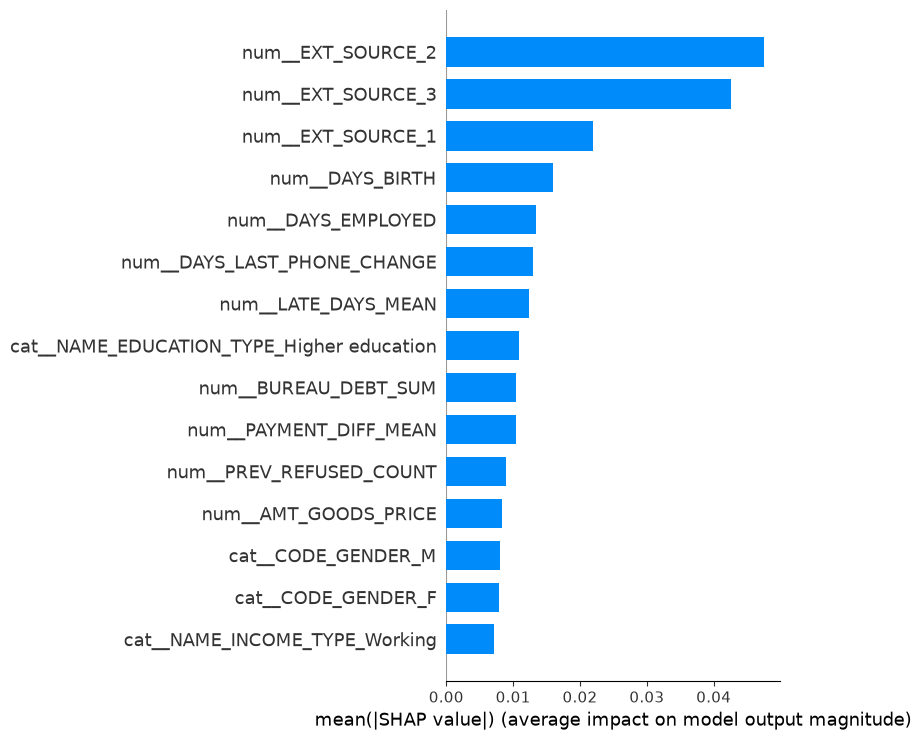

In [93]:
shap.summary_plot(
    shap_values[:, :, 1] if isinstance(shap_values, np.ndarray)
    and shap_values.ndim == 3 else shap_values[1],
    X_transformed,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15
)

a SHAP feature importance bar chart showing the top 15 features that most influence the Random Forest model’s predictions. It helps identify which factors contribute most to predicting clients with payment difficulties, making the model easier to interpret.

In [94]:
%pip install lime

Note: you may need to restart the kernel to use updated packages.


In [95]:
from lime.lime_tabular import LimeTabularExplainer

X_background = X_train_full.sample(500, random_state=42)

X_background_transformed = best_grid_rf.named_steps[
    "preprocessing"
].transform(X_background)

lime_explainer = LimeTabularExplainer(
    training_data=np.asarray(X_background_transformed),
    feature_names=feature_names,
    class_names=["Non-default", "Default"],
    mode="classification"
)

print("LIME explainer created!")

LIME explainer created!


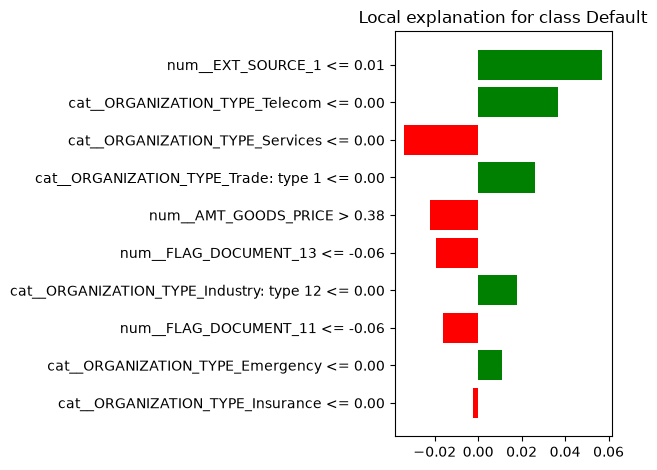

In [97]:
i = 0
applicant = X_test_full.iloc[i]

applicant_transformed = best_grid_rf.named_steps[
    "preprocessing"
].transform(applicant.to_frame().T)

lime_exp = lime_explainer.explain_instance(
    np.asarray(applicant_transformed).flatten(),
    best_grid_rf.named_steps["model"].predict_proba,
    num_features=10
)

lime_exp.as_pyplot_figure()
plt.tight_layout()
plt.show()


LIME (Local Interpretable Model-agnostic Explanations) to explain the prediction for one individual applicant. It identifies the top 10 features influencing that applicant’s predicted outcome and displays them in a chart, helping explain why the model predicts a particular risk of payment difficulties.

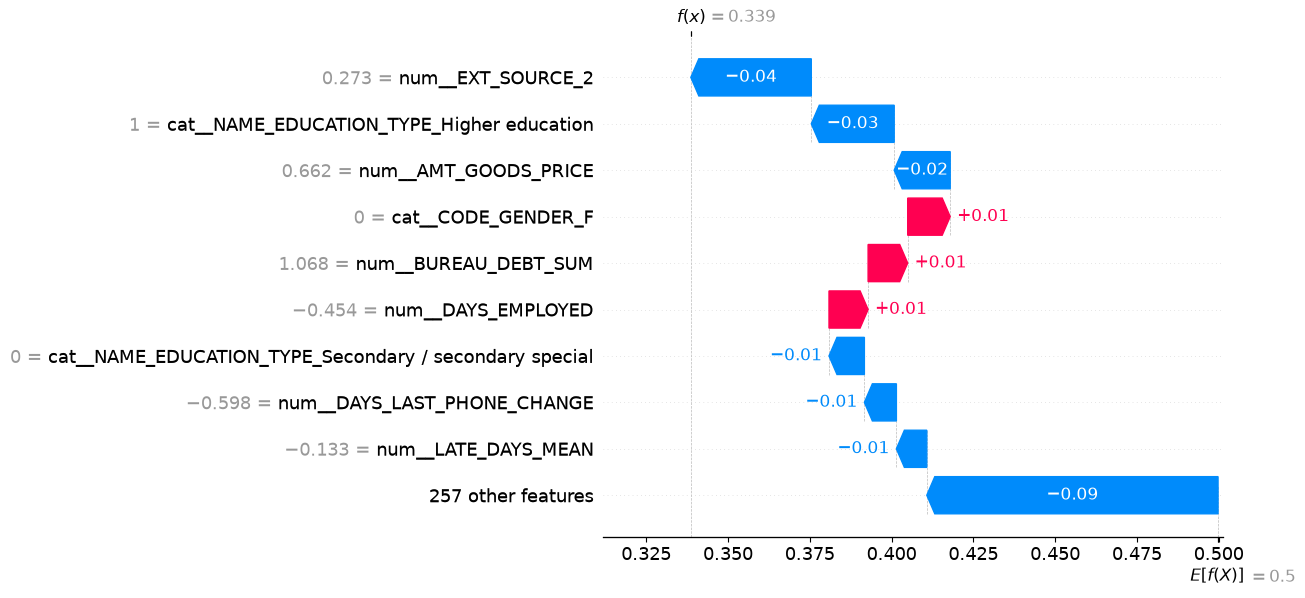

In [98]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0, :, 1],
        base_values=explainer.expected_value[1],
        data=np.asarray(X_transformed[0].toarray()).flatten()
            if hasattr(X_transformed[0], "toarray")
            else np.asarray(X_transformed[0]).flatten(),
        feature_names=feature_names
    ),
    max_display=10
)

a SHAP waterfall plot explaining one applicant’s prediction. It shows how the top 10 features increase or decrease the predicted risk of payment difficulties compared with the model’s average prediction.

In [102]:
final_model = grid_search.best_estimator_

final_pred = final_model.predict(X_test_full)

print(
    "Final Accuracy:",
    round(accuracy_score(y_test_full, final_pred), 4)
)

print(
    "Final Macro F1:",
    round(f1_score(y_test_full, final_pred, average="macro"), 4)
)

print("\nFinal Classification Report:")

print(
    classification_report(
        y_test_full,
        final_pred,
        zero_division=0
    )
)

Final Accuracy: 0.8048
Final Macro F1: 0.5874

Final Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.83      0.89     56538
           1       0.20      0.49      0.29      4965

    accuracy                           0.80     61503
   macro avg       0.58      0.66      0.59     61503
weighted avg       0.89      0.80      0.84     61503



evaluates the final tuned Random Forest model on the test dataset and prints its performance metrics. The model achieves 80.48% accuracy and a macro F1-score of 0.5874. The classification report shows that it identifies 49% of clients with payment difficulties, but the low precision of 20% means many predicted high-risk clients are false positives.

In [103]:
app_test = pd.read_csv("data/application_test.csv")

print("Test dataset shape:", app_test.shape)
display(app_test.head())

Test dataset shape: (48744, 121)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


loads the application_test.csv dataset, which contains 48,744 records and 121 columns. The first five rows show applicant details such as income, credit amount, family information, and credit bureau data. This dataset is used to make predictions for new applicants whose TARGET values are not provided.

In [104]:
app_test_full = app_test.merge(
    bureau_agg, on="SK_ID_CURR", how="left"
)

app_test_full = app_test_full.merge(
    previous_agg, on="SK_ID_CURR", how="left"
)

app_test_full = app_test_full.merge(
    installments_agg, on="SK_ID_CURR", how="left"
)

app_test_full = app_test_full.merge(
    credit_agg, on="SK_ID_CURR", how="left"
)

print("Test shape after feature engineering:", app_test_full.shape)

Test shape after feature engineering: (48744, 143)


adds the historical credit bureau, previous application, installment payment, and credit card summary features to the test dataset using SK_ID_CURR. The left merge keeps all 48,744 test applicants while adding information that helps the model assess their credit risk. After feature engineering, the test dataset has 48,744 rows and 143 columns, making it ready for prediction using the trained model.

In [105]:
X_app_test = app_test_full[X_train_full.columns]

print("Test features shape:", X_app_test.shape)
print("Matches training columns:", 
      list(X_app_test.columns) == list(X_train_full.columns))

Test features shape: (48744, 142)
Matches training columns: True


ts the same 142 feature columns from the test dataset that were used to train the model. The output shows a test feature shape of (48,744, 142) and Matches training columns: True, confirming that the training and test datasets have matching columns in the same order. This ensures the trained model can make predictions on the test data correctly.  

In [106]:
final_test_pred = final_model.predict(X_app_test)

final_test_prob = final_model.predict_proba(X_app_test)[:, 1]

print("Total applicants:", len(final_test_pred))
print("Predicted non-default:", (final_test_pred == 0).sum())
print("Predicted default:", (final_test_pred == 1).sum())

Total applicants: 48744
Predicted non-default: 39365
Predicted default: 9379


uses the trained model to predict whether each of the 48,744 test applicants may face payment difficulties. It also calculates the probability of default for each applicant. The output shows that 39,365 applicants are predicted as non-default, while 9,379 applicants are predicted as default. These are model predictions, not confirmed outcomes.

In [107]:
final_results = pd.DataFrame({
    "SK_ID_CURR": app_test_full["SK_ID_CURR"],
    "TARGET": final_test_pred,
    "DEFAULT_PROBABILITY": final_test_prob
})

display(final_results.head())

,SK_ID_CURR,TARGET,DEFAULT_PROBABILITY
0,100001,0,0.274879
1,100005,0,0.488656
2,100013,0,0.221587
3,100028,0,0.243936
4,100038,1,0.612394


creates a final results DataFrame containing each applicant’s ID (SK_ID_CURR), predicted target (TARGET), and default probability (DEFAULT_PROBABILITY). The output displays the first five predictions. A TARGET value of 0 indicates predicted non-default, while 1 indicates predicted payment difficulties. The probability indicates the model’s estimated risk of default for each applicant.

In [108]:
import joblib

joblib.dump(final_model, "HomeCreditModel.joblib")

print("Final model saved successfully!")

Final model saved successfully!


Final model saved